# Level 2 · Task 3 — K-Means Clustering
**Codveda Technology — Machine Learning Internship**

**Goal:** group unlabeled data into clusters. Here we do a **segmentation of S&P 500 stocks** by their trading behaviour —
the same idea as customer segmentation, but the "customers" are 505 companies.

**Dataset:** `stock_prices.csv` — daily prices & volume for 505 companies (2014–2017).

**Objectives covered**
1. Load the dataset and preprocess it (feature engineering + scaling)
2. Apply K-Means and find the optimal number of clusters with the elbow method (+ silhouette score as a check)
3. Visualize the clusters with 2-D scatter plots
4. Interpret the clustering results

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load & clean

In [2]:
prices = pd.read_csv(DATA / "stock_prices.csv", parse_dates=["date"])
prices = prices[prices["volume"] > 0].sort_values(["symbol", "date"])        # drop non-trading rows
print(prices.shape, "| companies:", prices["symbol"].nunique())
prices.head()

(497468, 7) | companies: 505


,symbol,date,open,high,low,close,volume
57,A,2014-01-02,57.10,57.100,56.15,56.21,1916160
540,A,2014-01-03,56.39,57.345,56.26,56.92,1866651
1023,A,2014-01-06,57.40,57.700,56.56,56.64,1777472
1506,A,2014-01-07,56.95,57.630,56.93,57.45,1463208
1989,A,2014-01-08,57.33,58.540,57.17,58.39,2659468


## 2. Build one row per company (feature engineering)
K-Means needs one feature vector per object. For each company we summarise its 4 years of trading:

| Feature | Meaning |
|---|---|
| `annual_return` | average daily return × 252 (growth) |
| `annual_volatility` | std of daily returns × √252 (risk) |
| `avg_intraday_range` | average (high − low) / close (how much it moves within a day) |
| `log_avg_dollar_volume` | log of average price × volume (size / liquidity of the stock) |
| `max_drawdown` | worst peak-to-trough fall (downside risk) |

Companies with less than one year of history (recent IPOs / spin-offs) are excluded, because their statistics would be unreliable.

In [3]:
prices["ret"] = prices.groupby("symbol")["close"].pct_change()
prices["range"] = (prices["high"] - prices["low"]) / prices["close"]
prices["dollar_vol"] = prices["close"] * prices["volume"]

def max_drawdown(close):
    return (close / close.cummax() - 1).min()

g = prices.groupby("symbol")
feat = pd.DataFrame({
    "n_days": g.size(),
    "annual_return": g["ret"].mean() * 252,
    "annual_volatility": g["ret"].std() * np.sqrt(252),
    "avg_intraday_range": g["range"].mean(),
    "log_avg_dollar_volume": np.log10(g["dollar_vol"].mean()),
    "max_drawdown": g["close"].apply(max_drawdown),
})
print("Companies with < 252 trading days:", (feat["n_days"] < 252).sum())
feat = feat[feat["n_days"] >= 252].drop(columns="n_days").dropna()
print("Companies kept:", len(feat))
feat.describe().T.round(3)

Companies with < 252 trading days: 6
Companies kept: 499


,count,mean,std,min,25%,50%,75%,max
annual_return,499.0,0.115,0.116,-0.584,0.050,0.120,0.178,0.696
annual_volatility,499.0,0.247,0.079,0.132,0.194,0.229,0.280,0.723
avg_intraday_range,499.0,0.019,0.005,0.011,0.016,0.018,0.022,0.052
log_avg_dollar_volume,499.0,8.213,0.350,7.136,7.973,8.174,8.407,9.698
max_drawdown,499.0,-0.356,0.163,-0.949,-0.447,-0.325,-0.232,-0.088


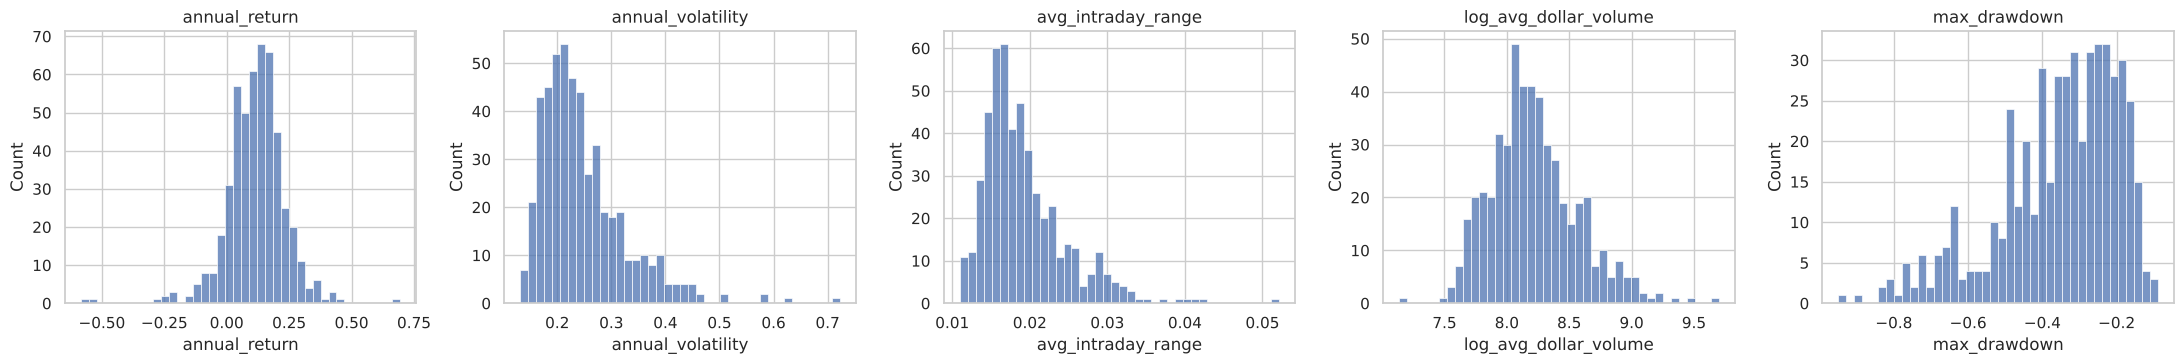

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(22, 3.8))
for ax, c in zip(axes, feat.columns):
    sns.histplot(feat[c], ax=ax, bins=40); ax.set_title(c)
plt.tight_layout(); plt.savefig(IMG / "feature_distributions.png", dpi=110); plt.show()

## 3. Scaling
K-Means uses Euclidean distance, so a feature measured in large units (dollar volume) would dominate one measured in
small units (daily range). We **standardize** all features (mean 0, std 1).

A few stocks have extreme values (e.g. a 90 % drawdown). To stop single outliers from getting their own cluster, values are
clipped at the 1st / 99th percentile before scaling.

In [5]:
features = list(feat.columns)
clipped = feat.clip(feat.quantile(0.01), feat.quantile(0.99), axis=1)
scaler = StandardScaler()
X = scaler.fit_transform(clipped)
print("Scaled means:", X.mean(axis=0).round(3), "\nScaled stds :", X.std(axis=0).round(3))

Scaled means: [ 0. -0. -0.  0. -0.] 
Scaled stds : [1. 1. 1. 1. 1.]


## 4. Choose the number of clusters — elbow method + silhouette score

In [6]:
ks = range(2, 11)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X, km.labels_))
elbow = pd.DataFrame({"k": ks, "inertia (WCSS)": inertia, "silhouette": silhouette})
elbow["inertia drop %"] = (-elbow["inertia (WCSS)"].pct_change() * 100)
elbow.round(3)

,k,inertia (WCSS),silhouette,inertia drop %
0,2,1542.889,0.429,NaN
1,3,1251.307,0.267,18.898
2,4,1031.982,0.284,17.528
3,5,852.370,0.285,17.405
4,6,769.670,0.287,9.702
5,7,708.637,0.252,7.930
6,8,658.555,0.244,7.067
7,9,615.698,0.239,6.508
8,10,578.087,0.232,6.109


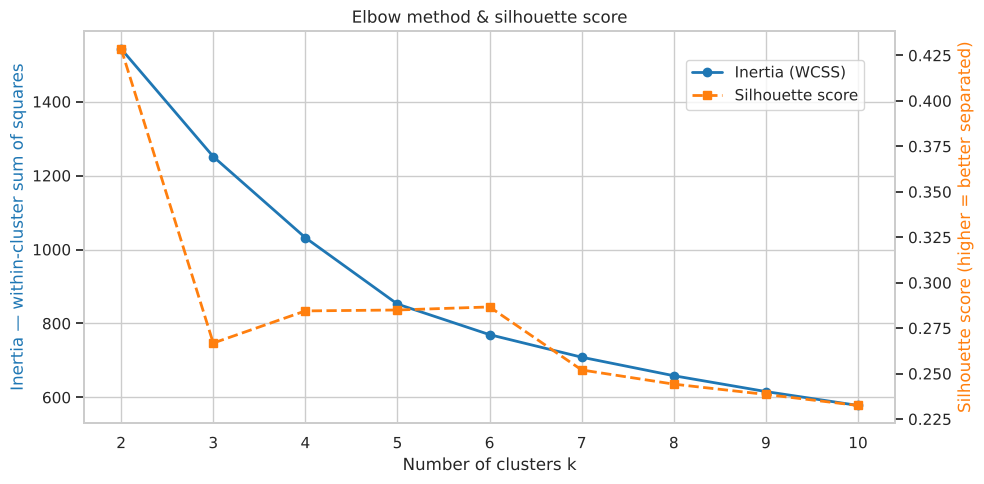

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(elbow["k"], elbow["inertia (WCSS)"], "o-", color="tab:blue", lw=2, label="Inertia (WCSS)")
ax1.set_xlabel("Number of clusters k"); ax1.set_ylabel("Inertia — within-cluster sum of squares", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(elbow["k"], elbow["silhouette"], "s--", color="tab:orange", lw=2, label="Silhouette score")
ax2.set_ylabel("Silhouette score (higher = better separated)", color="tab:orange"); ax2.grid(False)
ax1.set_title("Elbow method & silhouette score")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout(); plt.savefig(IMG / "elbow.png", dpi=120); plt.show()

In [8]:
# Kneedle-style elbow: the k whose point lies farthest from the straight line joining the first and last points of the curve
x = np.array(list(ks), dtype=float); y = np.array(inertia)
xn, yn = (x - x.min()) / (x.max() - x.min()), (y - y.min()) / (y.max() - y.min())
dist = np.abs(yn - (1 - xn)) / np.sqrt(2)
best_k = int(x[np.argmax(dist)])
print("Elbow (max distance to chord) at k =", best_k)
print("Silhouette at that k:", round(elbow.loc[elbow['k'] == best_k, 'silhouette'].item(), 3))

Elbow (max distance to chord) at k = 5
Silhouette at that k: 0.285


## 5. Fit the final K-Means model

In [9]:
kmeans = KMeans(n_clusters=best_k, n_init=50, random_state=RANDOM_STATE).fit(X)
feat["cluster"] = kmeans.labels_
print(feat["cluster"].value_counts().sort_index())

cluster
0    177
1     60
2     65
3     80
4    117
Name: count, dtype: int64


## 6. Visualize the clusters (2-D scatter plots)
* **Left:** the two most intuitive raw features — risk (volatility) vs reward (annual return).
* **Right:** all 5 features projected to 2-D with PCA (shows how well the clusters separate in the full feature space).

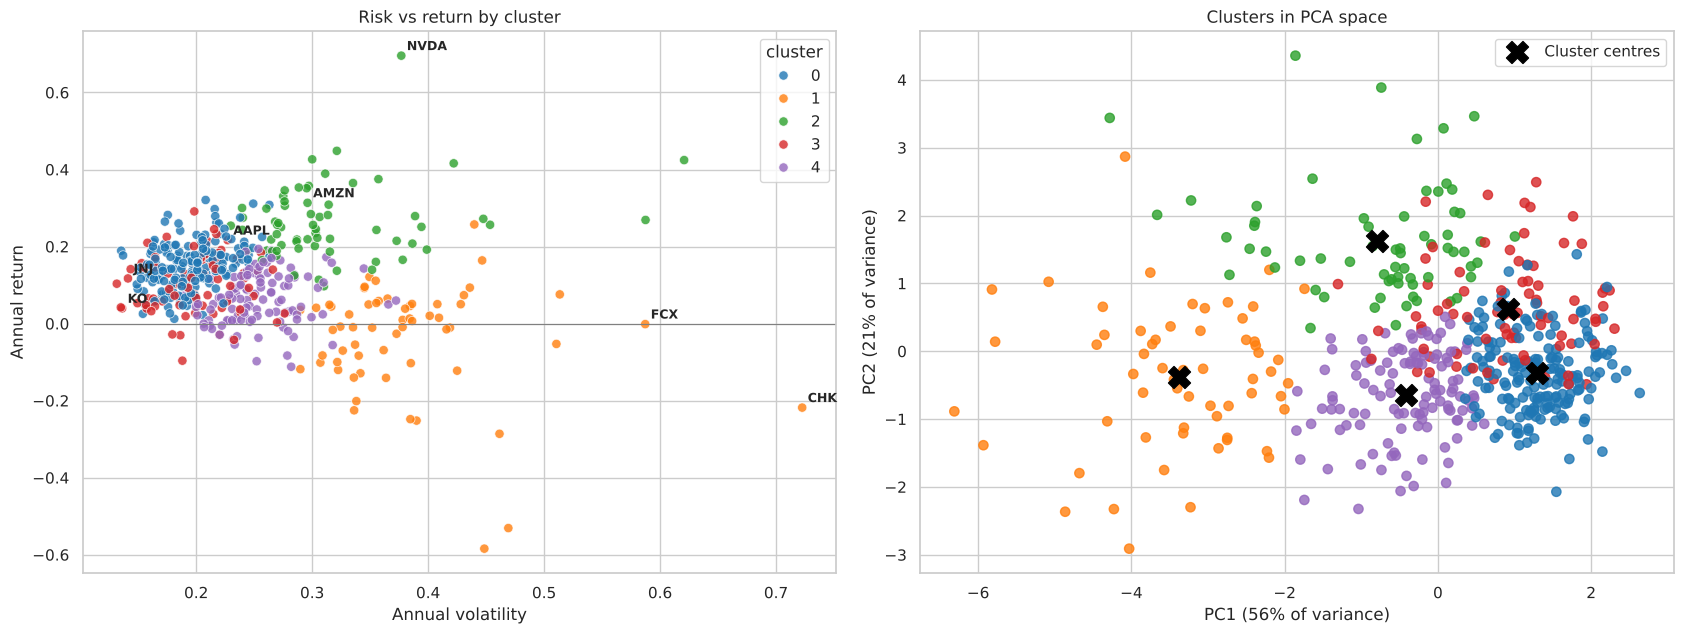

In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(X)
centers_pca = pca.transform(kmeans.cluster_centers_)
palette = sns.color_palette("tab10", best_k)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.scatterplot(data=feat, x="annual_volatility", y="annual_return", hue="cluster", palette=palette, s=45, alpha=.8, ax=axes[0])
axes[0].axhline(0, color="grey", lw=.8)
axes[0].set_title("Risk vs return by cluster"); axes[0].set_xlabel("Annual volatility"); axes[0].set_ylabel("Annual return")
for sym in ["AAPL", "AMZN", "NVDA", "KO", "JNJ", "CHK", "FCX"]:
    if sym in feat.index:
        axes[0].annotate(sym, (feat.loc[sym, "annual_volatility"], feat.loc[sym, "annual_return"]), fontsize=9,
                         xytext=(4, 4), textcoords="offset points", weight="bold")

axes[1].scatter(P[:, 0], P[:, 1], c=[palette[c] for c in kmeans.labels_], s=45, alpha=.8)
axes[1].scatter(centers_pca[:, 0], centers_pca[:, 1], c="black", marker="X", s=250, label="Cluster centres")
axes[1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
axes[1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
axes[1].set_title("Clusters in PCA space"); axes[1].legend()
plt.tight_layout(); plt.savefig(IMG / "clusters_2d.png", dpi=120); plt.show()

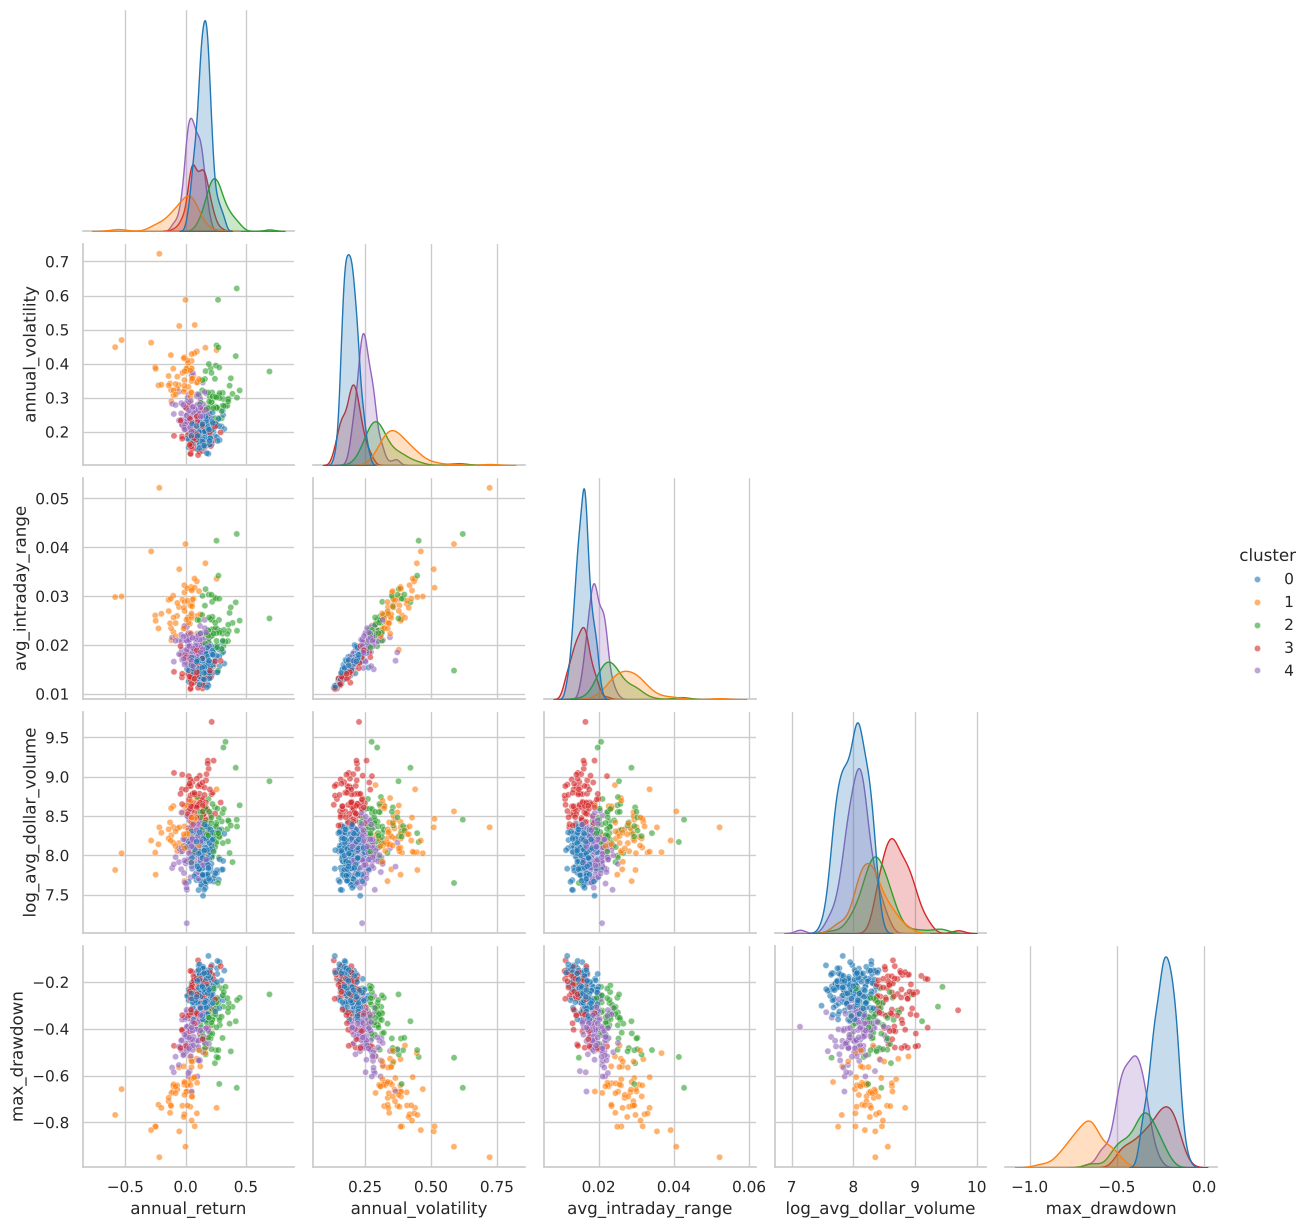

In [11]:
sns.pairplot(feat, hue="cluster", vars=features, palette=palette, corner=True, plot_kws={"alpha": .6, "s": 20})
plt.savefig(IMG / "pairplot_clusters.png", dpi=90, bbox_inches="tight"); plt.show()

## 7. Interpret the clusters

In [12]:
profile = feat.groupby("cluster")[features].mean()
profile.insert(0, "n_companies", feat["cluster"].value_counts().sort_index())
profile_fmt = profile.copy()
for c in ["annual_return", "annual_volatility", "avg_intraday_range", "max_drawdown"]:
    profile_fmt[c] = (profile_fmt[c] * 100).round(1).astype(str) + " %"
profile_fmt["typical_dollar_volume ($M/day)"] = (10 ** profile["log_avg_dollar_volume"] / 1e6).round(0)
profile_fmt.drop(columns="log_avg_dollar_volume")

,n_companies,annual_return,annual_volatility,avg_intraday_range,max_drawdown,typical_dollar_volume ($M/day)
cluster,,,,,,
0,177,15.2 %,19.4 %,1.6 %,-23.2 %,99.0
1,60,-3.9 %,38.2 %,2.8 %,-67.5 %,188.0
2,65,26.2 %,31.7 %,2.4 %,-37.2 %,246.0
3,80,10.3 %,19.9 %,1.5 %,-28.0 %,522.0
4,117,6.3 %,25.3 %,1.9 %,-42.4 %,116.0


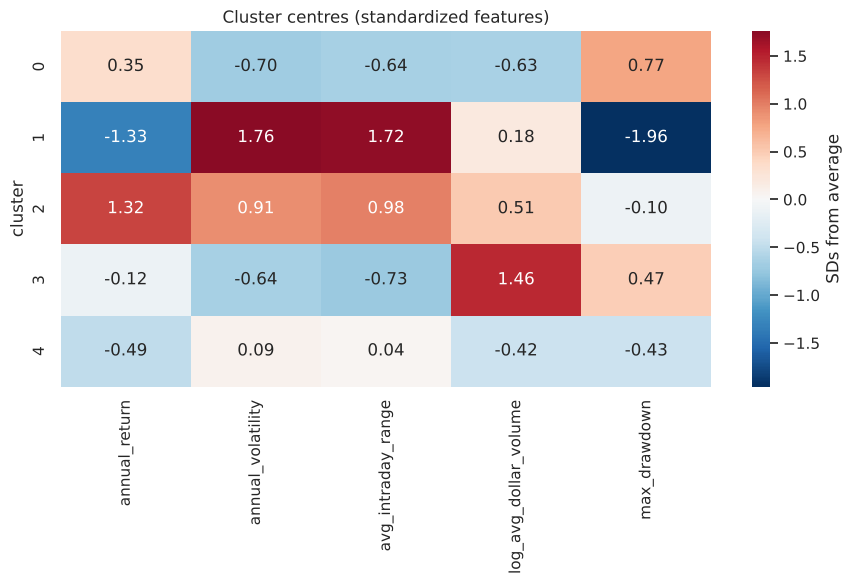

In [13]:
# Standardized cluster centres: how far (in SDs) each cluster is from the market average on each feature
centers = pd.DataFrame(kmeans.cluster_centers_, columns=features)
plt.figure(figsize=(9, 0.9 * best_k + 1.5))
sns.heatmap(centers, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "SDs from average"})
plt.title("Cluster centres (standardized features)"); plt.ylabel("cluster")
plt.tight_layout(); plt.savefig(IMG / "cluster_centres_heatmap.png", dpi=120); plt.show()

In [14]:
for c in range(best_k):
    members = feat[feat["cluster"] == c].sort_values("log_avg_dollar_volume", ascending=False).index[:12]
    print(f"Cluster {c} ({(feat['cluster'] == c).sum()} companies) — e.g. {', '.join(members)}")

Cluster 0 (177 companies) — e.g. ACN, TMO, PNC, NEE, AMT, GD, BLK, RTN, CCI, MAR, KMB, EQIX
Cluster 1 (60 companies) — e.g. AGN, MU, BIIB, HAL, EBAY, CMG, COP, KMI, FCX, APC, PXD, WYNN
Cluster 2 (65 companies) — e.g. FB, AMZN, NFLX, NVDA, CELG, ABBV, DAL, AVGO, AAL, MS, CHTR, PYPL
Cluster 3 (80 companies) — e.g. AAPL, BAC, MSFT, GOOGL, GOOG, GE, JPM, XOM, C, GILD, WFC, T
Cluster 4 (117 companies) — e.g. FOXA, OXY, CBS, MET, MCK, KR, PSX, YUM, CTSH, COF, BAX, EMR


In [15]:
Path("output").mkdir(exist_ok=True)
feat.sort_values("cluster").to_csv("output/stock_clusters.csv")
print("Saved output/stock_clusters.csv")

Saved output/stock_clusters.csv


## Conclusions
**Choosing k.** The inertia curve drops ~17–19 % per extra cluster up to k = 5, then only 6–10 % → the **elbow is at k = 5**.
The silhouette score is highest at k = 2 (0.43), but that split only separates "risky" from "calm" stocks; for k = 4–6 the
silhouette is flat (~0.28–0.29), so k = 5 gives more useful detail at no loss in separation quality.

**The 5 stock segments (2014–2017):**
| Cluster | Size | Profile | Typical members | Interpretation |
|---|---|---|---|---|
| 0 | 177 | +15 % / yr, lowest volatility (19 %), smallest drawdown (−23 %) | ACN, TMO, NEE, BLK, KMB | **Steady compounders** — quality defensive companies |
| 1 | 60 | **−4 % / yr**, highest volatility (38 %), drawdown −68 % | HAL, COP, FCX, APC, MU, BIIB | **Distressed / commodity-hit** — mostly energy & materials hurt by the 2014–16 oil crash |
| 2 | 65 | **+26 % / yr**, high volatility (32 %) | FB, AMZN, NFLX, NVDA, AVGO | **High-growth momentum** — big winners, but with bigger swings |
| 3 | 80 | +10 % / yr, low volatility, **by far the most traded** (~$520M/day) | AAPL, MSFT, GOOGL, JPM, XOM | **Mega-cap blue chips** — very liquid market leaders |
| 4 | 117 | +6 % / yr, average volatility, drawdown −42 % | OXY, CBS, MET, KR, YUM | **Under-performers** — average risk with below-market returns |

**Business use:** the segments map directly to portfolio roles — cluster 0/3 for low-risk core holdings, cluster 2 for growth,
and cluster 1 flagged as high-risk. The same pipeline (aggregate behaviour → scale → elbow → K-Means → profile) is exactly
how customer segmentation is done on transaction data.